# Punto 3 — RAG (*Retrieval-Augmented Generation*) implementado con **Ollama**

UNIVERSIDAD AUTÓNOMA DE OCCIDENTE — Inteligencia Artificial Generativa 2026-2S  
Entregable: *Modelos Generativos de Texto Basados en la Arquitectura Transformer*  
**Integrantes:** Sergio Gómez — Valeria Franco

## Problema a solucionar

Estudiantes del curso necesitan un **asistente de consulta sobre los artículos fundacionales de
los LLM** que vemos en clase. Un LLM pequeño ejecutado localmente (Llama 3.2 3B) no conoce los
detalles exactos de estos artículos (hiperparámetros, cifras, definiciones) y tiende a
**alucinarlos**. Con RAG el modelo responde **apoyándose en fragmentos recuperados** de los PDFs y
citando la fuente.

**Base de contexto (3 documentos PDF, arXiv):**
1. Vaswani et al. (2017) — *Attention Is All You Need* (arXiv:1706.03762)
2. Touvron et al. (2023) — *LLaMA: Open and Efficient Foundation Language Models* (arXiv:2302.13971)
3. Lewis et al. (2020) — *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (arXiv:2005.11401)

**Pipeline:** PDF → texto → *chunks* con solapamiento → embeddings (`nomic-embed-text` vía Ollama)
→ búsqueda por similitud coseno (top-k) → *prompt* con contexto → generación (`llama3.2:3b` vía Ollama).

**Evaluación:** conjunto de 12 preguntas con respuesta de referencia y documento fuente conocido;
se evalúa la **recuperación** (Hit@k, MRR, precisión de contexto) y la **generación**
(exactitud por palabras clave, similitud semántica, ROUGE-L, *faithfulness* y relevancia con
LLM-como-juez), comparando **RAG vs. el mismo LLM sin contexto**.

> Ejecutar en Colab con **GPU (T4)**.

## 1. Instalación y arranque de Ollama en Colab

In [1]:
!sudo apt-get -qq install -y zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!pip -q install pypdf rouge-score

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 12.7 MB/s eta 0:00:00


In [2]:
import subprocess, time, os
# Lanzamos el servidor de Ollama en segundo plano
server = subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
time.sleep(5)

LLM_MODEL = "llama3.2:3b"          # generador
EMB_MODEL = "nomic-embed-text"     # modelo de embeddings
!ollama pull {LLM_MODEL}
!ollama pull {EMB_MODEL}
!ollama list



NAME                       ID              SIZE      MODIFIED               
nomic-embed-text:latest    0a109f422b47    274 MB    Less than a second ago    
llama3.2:3b                a80c4f17acd5    2.0 GB    5 seconds ago             


In [3]:
import re, json, math, urllib.request
import numpy as np
import requests
from pypdf import PdfReader

OLLAMA = "http://localhost:11434"

def embed(texts):
    """Embeddings con Ollama (/api/embed acepta lotes)."""
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMB_MODEL, "input": texts})
    r.raise_for_status()
    e = np.array(r.json()["embeddings"], dtype="float32")
    return e / np.linalg.norm(e, axis=1, keepdims=True)     # normalizamos para coseno

def chat(prompt, system=None, temperature=0.0):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    r = requests.post(f"{OLLAMA}/api/chat", json={"model": LLM_MODEL, "messages": msgs, "stream": False,
                                                  "options": {"temperature": temperature, "num_ctx": 4096}})
    r.raise_for_status()
    return r.json()["message"]["content"].strip()

print(chat("Responde solo 'listo'."))

Listo.


## 2. Base de contexto: descarga y lectura de los 3 PDFs

In [4]:
DOCS = {
    "attention": ("Attention Is All You Need", "https://arxiv.org/pdf/1706.03762"),
    "llama": ("LLaMA: Open and Efficient Foundation Language Models", "https://arxiv.org/pdf/2302.13971"),
    "rag": ("Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks", "https://arxiv.org/pdf/2005.11401"),
}
os.makedirs("docs", exist_ok=True)
pages = []                                   # (doc_id, n_página, texto)
for doc_id, (title, url) in DOCS.items():
    path = f"docs/{doc_id}.pdf"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    for i, page in enumerate(PdfReader(path).pages):
        t = re.sub(r"\s+", " ", page.extract_text() or "").strip()
        if t:
            pages.append((doc_id, i + 1, t))
    print(f"{doc_id:<10} {sum(p[0] == doc_id for p in pages):>3} páginas — {title}")

attention   15 páginas — Attention Is All You Need
llama       27 páginas — LLaMA: Open and Efficient Foundation Language Models
rag         19 páginas — Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks


## 3. Fragmentación (*chunking*) e indexación

Fragmentos de ~800 caracteres con solapamiento de 150, cortando en límites de oración cuando es
posible. Cada fragmento conserva su documento y página para poder **citar la fuente**.

In [5]:
def chunk_text(t, size=800, overlap=150):
    chunks, start = [], 0
    while start < len(t):
        end = min(start + size, len(t))
        if end < len(t):                                   # retrocede al último punto
            cut = t.rfind(". ", start + size // 2, end)
            end = cut + 1 if cut != -1 else end
        chunks.append(t[start:end].strip())
        if end == len(t):
            break
        start = end - overlap
    return chunks

chunks = [{"doc": d, "page": p, "text": c} for d, p, t in pages for c in chunk_text(t)]
print("Fragmentos:", len(chunks))

# Embeddings por lotes (nomic-embed-text usa prefijos de tarea)
E = np.vstack([embed([f"search_document: {c['text']}" for c in chunks[i:i + 32]])
               for i in range(0, len(chunks), 32)])
print("Matriz de embeddings:", E.shape)

Fragmentos: 351
Matriz de embeddings: (351, 768)


## 4. Recuperación y generación aumentada

In [6]:
def retrieve(question, k=4):
    q = embed([f"search_query: {question}"])[0]
    sims = E @ q
    top = np.argsort(-sims)[:k]
    return [{**chunks[i], "score": float(sims[i])} for i in top]

SYSTEM = ("Eres un asistente que responde preguntas sobre artículos de investigación en IA. "
          "Responde SOLO con la información del CONTEXTO. Si el contexto no contiene la respuesta, "
          "di 'No lo sé con la información disponible'. Responde en español, de forma breve, y cita "
          "las fuentes como [doc p.N].")

def rag_answer(question, k=4):
    ctx = retrieve(question, k)
    context = "\n\n".join(f"[{c['doc']} p.{c['page']}] {c['text']}" for c in ctx)
    prompt = f"CONTEXTO:\n{context}\n\nPREGUNTA: {question}\nRESPUESTA:"
    return chat(prompt, SYSTEM), ctx

def no_rag_answer(question):
    return chat(f"Responde en español, de forma breve.\nPREGUNTA: {question}\nRESPUESTA:")

q = "¿Qué función de activación usa LLaMA en la red feed-forward y por qué?"
ans, ctx = rag_answer(q)
print(ans, "\n\nFuentes:", [(c["doc"], c["page"], round(c["score"], 3)) for c in ctx])

No lo sé con la información disponible. 

Fuentes: [('llama', 7, 0.56), ('llama', 1, 0.551), ('llama', 7, 0.549), ('llama', 7, 0.543)]


## 5. Conjunto de evaluación

12 preguntas (4 por documento) con **respuesta de referencia**, **palabras clave** que una
respuesta correcta debe contener y **documento fuente**. Incluimos además 2 preguntas
*fuera de dominio* para medir si el sistema se abstiene en lugar de alucinar.

In [7]:
EVAL = [
    # (pregunta, doc_fuente, respuesta_referencia, palabras_clave)
    ("¿Cuántas cabezas de atención usa el modelo Transformer base?", "attention",
     "El modelo base usa 8 cabezas de atención paralelas (h = 8).", ["8"]),
    ("¿Cuál es la dimensión d_model del Transformer base?", "attention",
     "d_model = 512.", ["512"]),
    ("¿Qué BLEU obtuvo el Transformer grande en la traducción inglés-alemán WMT 2014?", "attention",
     "Obtuvo 28.4 BLEU en WMT 2014 inglés-alemán.", ["28.4"]),
    ("¿Por qué se escala el producto punto por 1/sqrt(d_k) en la atención?", "attention",
     "Porque para valores grandes de d_k los productos punto crecen y empujan el softmax a regiones "
     "con gradientes muy pequeños; escalar por 1/sqrt(d_k) lo contrarresta.", ["gradient", "softmax"]),
    ("¿Qué tipo de normalización usa LLaMA y dónde la aplica?", "llama",
     "Usa RMSNorm aplicada a la entrada de cada subcapa (pre-normalización).", ["rmsnorm"]),
    ("¿Qué función de activación usa LLaMA en la red feed-forward?", "llama",
     "Usa la activación SwiGLU (en lugar de ReLU), con dimensión 2/3·4d.", ["swiglu"]),
    ("¿Qué tipo de codificación posicional usa LLaMA?", "llama",
     "Usa embeddings posicionales rotatorios (RoPE) en lugar de embeddings posicionales absolutos.", ["rota", "rope"]),
    ("¿Con cuántos tokens se entrenaron los modelos LLaMA de 33B y 65B?", "llama",
     "Se entrenaron con 1.4 billones (trillion) de tokens.", ["1.4"]),
    ("¿Qué dos componentes combina el modelo RAG?", "rag",
     "Combina una memoria paramétrica (un generador seq2seq preentrenado, BART) y una memoria no "
     "paramétrica (un índice denso de Wikipedia accedido con un recuperador neuronal, DPR).", ["bart", "wikipedia"]),
    ("¿Cuál es la diferencia entre RAG-Sequence y RAG-Token?", "rag",
     "RAG-Sequence usa el mismo documento recuperado para generar toda la secuencia; RAG-Token puede "
     "usar un documento distinto para cada token.", ["token", "secuencia"]),
    ("¿Qué recuperador usa RAG?", "rag",
     "Usa Dense Passage Retriever (DPR) con un codificador de consultas basado en BERT y búsqueda MIPS.", ["dpr"]),
    ("¿Qué modelo generador usa RAG?", "rag",
     "Usa BART-large como generador seq2seq.", ["bart"]),
]
OUT_OF_DOMAIN = ["¿Cuál es la capital de Mongolia según estos artículos?",
                 "¿Qué resultados obtiene GPT-4 en el examen de abogacía según los documentos?"]

## 6. Evaluación de la recuperación

Para cada pregunta, un fragmento se considera **relevante** si pertenece al documento fuente
**y** contiene alguna de las palabras clave de la respuesta.

* **Hit@k**: % de preguntas con al menos un fragmento relevante en el top-k.
* **MRR** (*Mean Reciprocal Rank*): promedio de `1/posición` del primer fragmento relevante.
* **Precisión de contexto@k**: fracción de los k fragmentos que son relevantes.
* **Doc-Hit@1**: el primer fragmento proviene del documento correcto.

In [8]:
def strip_accents(s):
    import unicodedata
    return "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn")

# Palabras clave en inglés equivalentes para buscar dentro de los PDFs (escritos en inglés)
KW_EN = {"secuencia": "sequence"}

def is_relevant(c, doc, kws):
    t = strip_accents(c["text"])
    return c["doc"] == doc and any(KW_EN.get(k, k) in t for k in kws)

K = 4
hits, rr, prec, doc1 = [], [], [], []
for q, doc, _, kws in EVAL:
    ctx = retrieve(q, K)
    rel = [is_relevant(c, doc, kws) for c in ctx]
    hits.append(any(rel)); prec.append(np.mean(rel)); doc1.append(ctx[0]["doc"] == doc)
    rr.append(1 / (rel.index(True) + 1) if any(rel) else 0.0)

print(f"Hit@{K}: {np.mean(hits):.2f} | MRR: {np.mean(rr):.2f} | "
      f"Precisión de contexto@{K}: {np.mean(prec):.2f} | Doc-Hit@1: {np.mean(doc1):.2f}")

Hit@4: 0.58 | MRR: 0.41 | Precisión de contexto@4: 0.25 | Doc-Hit@1: 0.92


## 7. Evaluación de la generación: RAG vs. sin RAG

* **Exactitud por palabras clave**: la respuesta contiene la(s) palabra(s) clave (p. ej. "512", "SwiGLU").
* **Similitud semántica** coseno entre los embeddings de la respuesta y de la referencia.
* **ROUGE-L (F1)** respecto a la referencia (solapamiento léxico).
* **LLM-como-juez** (mismo modelo, temperatura 0), escala 1–5:
  * **Corrección** frente a la referencia.
  * **Fidelidad (*faithfulness*)**: ¿la respuesta está sustentada por el contexto recuperado? (solo RAG)
* **Abstención** en preguntas fuera de dominio.

In [9]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rougeL"])

def judge(instruction):
    out = chat(instruction + "\nResponde ÚNICAMENTE con un número entero del 1 al 5.")
    m = re.search(r"[1-5]", out)
    return int(m.group()) if m else 1

def correctness(q, ref, ans):
    return judge(f"Pregunta: {q}\nRespuesta de referencia: {ref}\nRespuesta evaluada: {ans}\n"
                 "¿Qué tan correcta es la respuesta evaluada respecto a la referencia? (5 = totalmente correcta)")

def faithfulness(ans, ctx):
    context = "\n".join(c["text"] for c in ctx)
    return judge(f"Contexto:\n{context}\n\nRespuesta: {ans}\n"
                 "¿Qué tanto de la respuesta está respaldado por el contexto? (5 = todo respaldado, 1 = inventado)")

def keyword_hit(ans, kws):
    a = strip_accents(ans)
    return float(any(strip_accents(k) in a or KW_EN.get(k, "~") in a for k in kws))

results = []
for q, doc, ref, kws in EVAL:
    ans_rag, ctx = rag_answer(q)
    ans_base = no_rag_answer(q)
    e_ref = embed([ref])[0]
    row = {"q": q}
    for name, ans in [("rag", ans_rag), ("base", ans_base)]:
        row[f"{name}_ans"] = ans
        row[f"{name}_kw"] = keyword_hit(ans, kws)
        row[f"{name}_sim"] = float(embed([ans])[0] @ e_ref)
        row[f"{name}_rougeL"] = scorer.score(ref, ans)["rougeL"].fmeasure
        row[f"{name}_correct"] = correctness(q, ref, ans)
    row["rag_faith"] = faithfulness(ans_rag, ctx)
    results.append(row)
    print(f"· {q}\n   RAG : {ans_rag[:160]}\n   BASE: {ans_base[:160]}\n")

· ¿Cuántas cabezas de atención usa el modelo Transformer base?
   RAG : Según la información proporcionada en el contexto, el modelo Transformer base utiliza 8 cabezas de atención.
   BASE: El modelo Transformer base utiliza 12 capas de atención.

· ¿Cuál es la dimensión d_model del Transformer base?
   RAG : Según la información proporcionada en el contexto, la dimensión d_model del Transformer base es de 512.
   BASE: La dimensión d_model del Transformer base es de 768.

· ¿Qué BLEU obtuvo el Transformer grande en la traducción inglés-alemán WMT 2014?
   RAG : El Transformer grande obtuvo un BLEU de 28.4 en la traducción inglés-alemán WMT 2014.
   BASE: Bleu 04 obtuvo el Transformer grande en la traducción inglés-alemán WMT 2014.

· ¿Por qué se escala el producto punto por 1/sqrt(d_k) en la atención?
   RAG : Según [attention p.4], se escala el producto punto por 1/√dk para "counteractar el efecto de que los gradientes del softmax se vuelven extremadamente pequeños e
   BASE: La esca

In [10]:
import pandas as pd
df = pd.DataFrame(results)
summary = pd.DataFrame({
    "Exactitud palabras clave": [df.rag_kw.mean(), df.base_kw.mean()],
    "Similitud semántica": [df.rag_sim.mean(), df.base_sim.mean()],
    "ROUGE-L F1": [df.rag_rougeL.mean(), df.base_rougeL.mean()],
    "Corrección juez (1-5)": [df.rag_correct.mean(), df.base_correct.mean()],
    "Fidelidad juez (1-5)": [df.rag_faith.mean(), np.nan],
}, index=["RAG (llama3.2:3b + contexto)", "Sin RAG (llama3.2:3b)"]).round(3)
summary

,Exactitud palabras clave,Similitud semántica,ROUGE-L F1,Corrección juez (1-5),Fidelidad juez (1-5)
RAG (llama3.2:3b + contexto),0.500,0.672,0.212,3.75,3.583
Sin RAG (llama3.2:3b),0.083,0.676,0.210,2.75,NaN


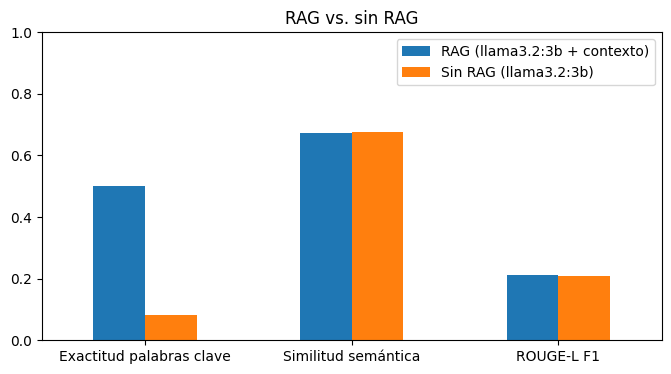

In [11]:
import matplotlib.pyplot as plt
cols = ["Exactitud palabras clave", "Similitud semántica", "ROUGE-L F1"]
summary[cols].T.plot(kind="bar", figsize=(8, 4), rot=0, title="RAG vs. sin RAG")
plt.ylim(0, 1); plt.show()

In [12]:
# Abstención ante preguntas cuya respuesta NO está en los documentos
ABST = ["no lo sé", "no lo se", "no se menciona", "no contiene", "no hay información", "no tengo"]
for q in OUT_OF_DOMAIN:
    ans, _ = rag_answer(q)
    print(f"· {q}\n  → {ans}\n  Se abstiene: {any(a in ans.lower() for a in ABST)}\n")

· ¿Cuál es la capital de Mongolia según estos artículos?
  → No lo sé con la información disponible.
  Se abstiene: True

· ¿Qué resultados obtiene GPT-4 en el examen de abogacía según los documentos?
  → No lo sé con la información disponible.
  Se abstiene: True



## 8. Conclusiones

Resultados obtenidos en Colab con GPU T4, `llama3.2:3b` y `nomic-embed-text` (351 fragmentos).

| Métrica | RAG | Sin RAG |
|---|---|---|
| Exactitud por palabras clave | **0.500** | 0.083 |
| Similitud semántica con la referencia | 0.672 | 0.676 |
| ROUGE-L F1 | 0.212 | 0.210 |
| Corrección según el juez (1-5) | **3.75** | 2.75 |
| Fidelidad al contexto según el juez (1-5) | 3.58 | — |

Recuperación (k = 4): Hit@4 = 0.58, MRR = 0.41, precisión de contexto@4 = 0.25, Doc-Hit@1 = 0.92.

* **RAG multiplica por 6 la exactitud en datos concretos** (0.50 frente a 0.08). Sin contexto el
  modelo inventa cifras: dice 768 en lugar de 512 para `d_model`, "12 capas de atención" en lugar de 8 cabezas, y
  confunde RAG con un "Recurrent Active Graph". Con contexto acierta 512, 8 cabezas y 28.4 BLEU.
* **La recuperación es el cuello de botella.** El documento correcto aparece primero en el 92 % de
  las preguntas, pero el fragmento exacto con la respuesta solo está entre los 4 recuperados en el
  58 %. Las 4 preguntas sobre LLaMA (RMSNorm, SwiGLU, RoPE, 1.4T tokens) fallaron por esto: el
  modelo recibió fragmentos que no contenían el dato y respondió "No lo sé". Es el
  comportamiento correcto (no alucina), pero son respuestas perdidas. Una búsqueda híbrida
  (BM25 + densa), un *re-ranker* o fragmentos más pequeños deberían corregirlo.
* **La similitud semántica y ROUGE-L casi no distinguen** los dos sistemas: una respuesta con la
  cifra equivocada se parece tanto a la referencia como una correcta. Por eso la exactitud por
  palabras clave y el juez son las métricas que muestran la diferencia.
* **Abstención:** ante las 2 preguntas fuera de los documentos (capital de Mongolia, GPT-4 en el
  examen de abogacía) el sistema respondió "No lo sé" en ambos casos.
* **Limitaciones:** el juez es el mismo modelo de 3B (sesgo de autoevaluación) y alguna respuesta
  con RAG sigue siendo imprecisa (p. ej. nombra RAG-Sequence como "generador" en vez de BART);
  el conjunto de 12 preguntas es pequeño. Para una evaluación más robusta se podría usar RAGAS con
  un juez más grande.